# makemore: Part 3.1 – Deep Layer Diagnostics


## 1. Setup & Dataset Preparation
### 1.1 Imports & Device Configuration


In [2]:
import torch
import random
import torch.nn.functional as F
import matplotlib.pyplot as plt

from pathlib import Path

In [4]:
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f'Using device: {device}')

Using device: cuda


### 1.2 Vocabulary & Dataset Splits


In [205]:
DATA_DIR = Path.cwd().parent / "data"
DATA_PATH = DATA_DIR / "names.txt"

words = DATA_PATH.read_text("utf-8").splitlines()
words[:10]

['emma',
 'olivia',
 'ava',
 'isabella',
 'sophia',
 'charlotte',
 'mia',
 'amelia',
 'harper',
 'evelyn']

In [206]:
# Build the vocabulary of characters and mappings to/from integer
chars = sorted(list(set(''.join(words))))
stoi = {s: i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i: s for s, i in stoi.items()}

In [207]:
# Build the dataset
block_size = 4

def build_dataset(words):  
  X, y = [], []
  
  for w in words:
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      y.append(ix)
      context = context[1:] + [ix]

  X = torch.tensor(X, device=device)
  y = torch.tensor(y, device=device)
  return X, y


random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr,  Ytr  = build_dataset(words[:n1])     # 80%
Xdev, Ydev = build_dataset(words[n1:n2])   # 10%
Xte,  Yte  = build_dataset(words[n2:])     # 10%


## 2. Modular Layer Implementations (Linear, Tanh, BatchNorm1d)


In [208]:
class Linear:
    def __init__(self, in_features, out_features, bias=True):
        self.weight = torch.randn(out_features, in_features, device=device)
        self.bias = torch.zeros(out_features, device=device) if bias else None

    def __call__(self, x):
        self.out = x @ self.weight.T
        if self.bias is not None:
            self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weight] + ([] if self.bias is None else [self.bias])


class Tanh:
    def __call__(self, x):
        self.out = torch.tanh(x)
        return self.out

    def parameters(self):
        return []

class BatchNorm1d:
    def __init__(self, num_features: int, eps: float = 0.00001, momentum: float = 0.1):
        self.eps = eps
        self.momentum = momentum
        self.training = True

        self.gamma = torch.ones(num_features, device=device)
        self.beta  = torch.zeros(num_features, device=device)

        self.running_mean = torch.zeros(num_features, device=device)
        self.running_var  = torch.ones(num_features, device=device)

    def __call__(self, x: torch.Tensor):
        if self.training:
            xmean = x.mean(dim=0)
            xvar  = x.var(dim=0)
        else:
            xmean = self.running_mean
            xvar = self.running_var

        xhat = (x - xmean) / torch.sqrt(xvar + self.eps)

        if self.training:
            with torch.no_grad():
                self.running_mean = (1 - self.momentum) * self.running_mean + self.momentum * xmean
                self.running_var  = (1 - self.momentum) * self.running_var + self.momentum * xvar

        self.out = self.gamma * xhat + self.beta
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

## 3. Deep MLP without BatchNorm (Baseline)

### 3.1 Model Initialization & Training


In [209]:
n_embd = 10
vocab_size = 27
hidden_size = 300

C = torch.randn((vocab_size, n_embd), device=device)

layers = [
    Linear(n_embd * block_size, hidden_size), Tanh(),
    Linear(hidden_size, hidden_size), Tanh(),
    Linear(hidden_size, hidden_size), Tanh(),
    Linear(hidden_size, hidden_size), Tanh(),
    Linear(hidden_size, hidden_size), Tanh(),
    Linear(hidden_size, hidden_size), Tanh(),
    Linear(hidden_size, hidden_size), Tanh(),
    Linear(hidden_size, hidden_size), Tanh(),
    Linear(hidden_size, hidden_size), Tanh(),
    Linear(hidden_size, vocab_size)
]

# Scaling the last layer
layers[-1].weight *= 0.01

for layer in layers:
    if isinstance(layer, Linear):
        layer.weight *= (layer.weight.shape[1] ** -0.5) * 5/3 ### Adjust the gain




parameters = [C] + [p for layer in layers for p in layer.parameters()]
print("Number of parameters:",sum(p.nelement() for p in parameters))

# Enable gradient tracking
for p in parameters:
    p.requires_grad = True

Number of parameters: 743097


In [1]:
max_steps = 100000
batch_size = 128
lossi = []
ud = [] # Update to data ratio

for i in range(max_steps):
  # Mini Batch
  ix = torch.randint(0, len(Xtr), (batch_size,), device=device)
  Xb, Yb = Xtr[ix], Ytr[ix] 
  
  # forward pass
  x = C[Xb].view(-1, n_embd * block_size)

  for layer in layers:
    x = layer(x)

  loss = F.cross_entropy(x, Yb)  
  for layer in layers:
    layer.out.retain_grad()
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1

  for p in parameters:
    p.data += -lr * p.grad

  if i % 1000 == 0:
    print(f"Steps: {i:7d} | Loss: {loss.item():.4f}")

  lossi.append(loss.item())
  with torch.no_grad():
    # Here since the mean of the weights and grads are ~ 0, so their std ~ RMS (typical magnitute)
    ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])
    
  if i > 10000: # Change this to view how the mean and std is changing across the layer during training...
    break

NameError: name 'torch' is not defined

### 3.2 Layer Diagnostics (Activations, Gradients & Updates)


layer 1 (      Tanh): mean -0.01, std 0.80, saturated: 30.20%
layer 3 (      Tanh): mean +0.00, std 0.76, saturated: 19.12%
layer 5 (      Tanh): mean +0.00, std 0.76, saturated: 19.19%
layer 7 (      Tanh): mean -0.00, std 0.76, saturated: 18.58%
layer 9 (      Tanh): mean +0.01, std 0.77, saturated: 18.90%
layer 11 (      Tanh): mean -0.01, std 0.78, saturated: 19.25%
layer 13 (      Tanh): mean +0.01, std 0.78, saturated: 20.79%
layer 15 (      Tanh): mean +0.02, std 0.79, saturated: 21.18%
layer 17 (      Tanh): mean +0.02, std 0.72, saturated: 12.38%


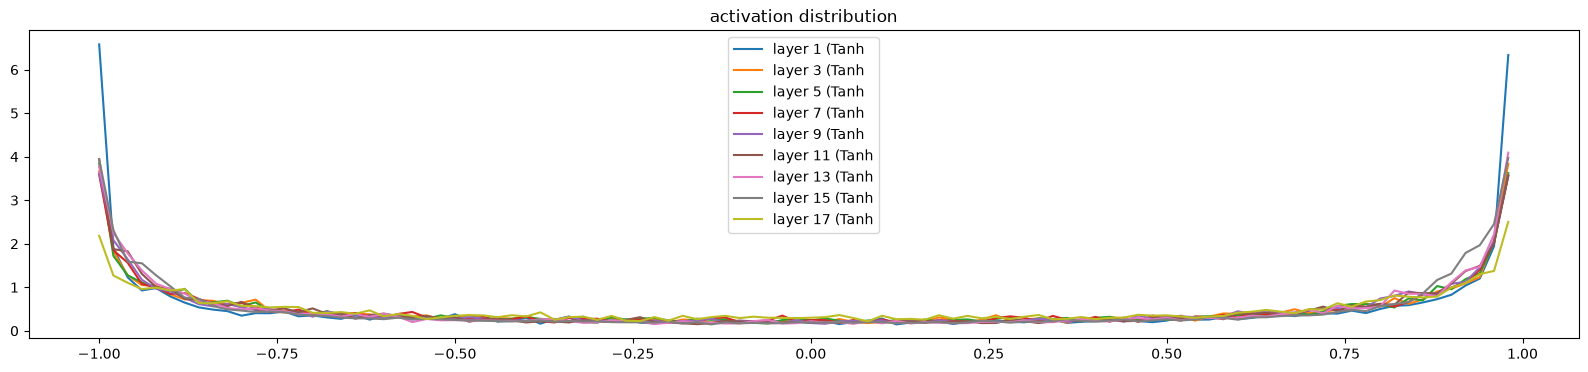

In [175]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t.cpu(), density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends)
plt.title('activation distribution');

In [2]:
# Gradient Distribution
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t.cpu(), density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution')

NameError: name 'plt' is not defined

weight   (27, 10) | mean -0.000603 | std 7.311870e-03 | grad:data ratio 7.110284e-03
weight  (300, 40) | mean -0.000015 | std 3.485578e-03 | grad:data ratio 1.327772e-02
weight (300, 300) | mean +0.000002 | std 2.733819e-03 | grad:data ratio 2.830032e-02
weight (300, 300) | mean +0.000001 | std 2.398475e-03 | grad:data ratio 2.481036e-02
weight (300, 300) | mean +0.000001 | std 2.294002e-03 | grad:data ratio 2.380935e-02
weight (300, 300) | mean +0.000016 | std 2.164557e-03 | grad:data ratio 2.244123e-02
weight (300, 300) | mean +0.000000 | std 2.029614e-03 | grad:data ratio 2.109689e-02
weight (300, 300) | mean +0.000002 | std 1.865995e-03 | grad:data ratio 1.933097e-02
weight (300, 300) | mean -0.000005 | std 1.736951e-03 | grad:data ratio 1.803809e-02
weight (300, 300) | mean +0.000002 | std 1.416590e-03 | grad:data ratio 1.472250e-02
weight  (27, 300) | mean +0.000000 | std 1.023738e-02 | grad:data ratio 2.895837e-01


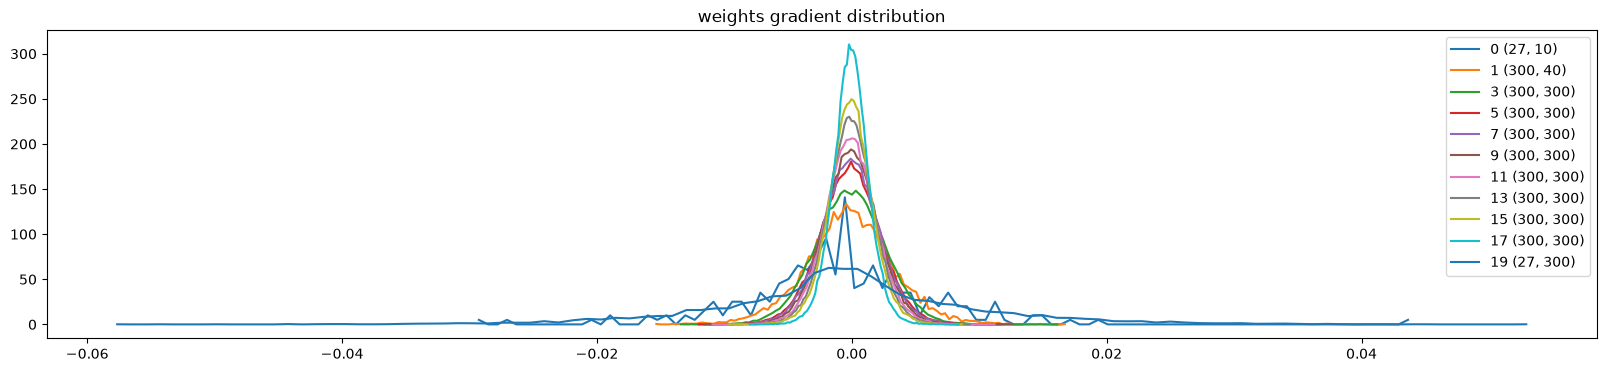

In [168]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t.cpu(), density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

In [1]:
# Update-to-data ratio
plt.figure(figsize=(20, 4))
legends = []
for i,p in enumerate(parameters):
  if p.ndim == 2:
    plt.plot([ud[j][i] for j in range(len(ud))])
    legends.append('param %d' % i)
plt.plot([0, len(ud)], [-3, -3], 'k') # these ratios should be ~1e-3, indicate on plot
plt.legend(legends);


NameError: name 'plt' is not defined

## 4. Deep MLP with BatchNorm

### 4.1 Model Initialization & Training


In [196]:
n_embd = 10
vocab_size = 27
hidden_size = 300

C = torch.randn((vocab_size, n_embd), device=device)

layers = [
    Linear(n_embd * block_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, hidden_size, bias=False), BatchNorm1d(hidden_size), Tanh(),
    Linear(hidden_size, vocab_size, bias=True) # Last layer has no BatchNorm, so keep bias=True
]

# Scaling the last layer
layers[-1].weight *= 0.01

for layer in layers:
    if isinstance(layer, Linear):
        layer.weight *= 1.0


parameters = [C] + [p for layer in layers for p in layer.parameters()]
print("Number of parameters:",sum(p.nelement() for p in parameters))


# Enable gradient tracking
for p in parameters:
    p.requires_grad = True

Number of parameters: 745797


In [197]:
max_steps = 100000
batch_size = 128
lossi = []
ud = [] # Update to data ratio

for i in range(max_steps):
  # Mini Batch
  ix = torch.randint(0, len(Xtr), (batch_size,), device=device)
  Xb, Yb = Xtr[ix], Ytr[ix] 
  
  # forward pass
  x = C[Xb].view(-1, n_embd * block_size)

  for layer in layers:
    x = layer(x)

  loss = F.cross_entropy(x, Yb)  
  for layer in layers:
    layer.out.retain_grad()
  for p in parameters:
    p.grad = None
  loss.backward()
  
  # update
  lr = 0.1

  for p in parameters:
    p.data += -lr * p.grad

  if i % 1000 == 0:
    print(f"Steps: {i:7d} | Loss: {loss.item():.4f}")

  lossi.append(loss.item())
  with torch.no_grad():
    # Here since the mean of the weights and grads are ~ 0, so their std ~ RMS (typical magnitute)
    ud.append([((lr*p.grad).std() / p.data.std()).log10().item() for p in parameters])
    
  if i > 10000: # Change this to view how the mean and std is changing across the layer during training.
    break

Steps:       0 | Loss: 3.2747
Steps:    1000 | Loss: 2.4408
Steps:    2000 | Loss: 2.1143
Steps:    3000 | Loss: 2.1636
Steps:    4000 | Loss: 2.4030
Steps:    5000 | Loss: 2.2364
Steps:    6000 | Loss: 2.1336
Steps:    7000 | Loss: 2.0447
Steps:    8000 | Loss: 2.2459
Steps:    9000 | Loss: 2.2593
Steps:   10000 | Loss: 2.3370


### 4.2 Layer Diagnostics (Activations & Gradients)


layer 2 (      Tanh): mean -0.00, std 0.62, saturated: 2.88%
layer 5 (      Tanh): mean -0.00, std 0.63, saturated: 2.91%
layer 8 (      Tanh): mean +0.00, std 0.63, saturated: 2.95%
layer 11 (      Tanh): mean +0.00, std 0.63, saturated: 2.81%
layer 14 (      Tanh): mean -0.01, std 0.63, saturated: 2.72%
layer 17 (      Tanh): mean +0.00, std 0.63, saturated: 3.04%
layer 20 (      Tanh): mean +0.00, std 0.63, saturated: 3.08%
layer 23 (      Tanh): mean -0.00, std 0.64, saturated: 3.16%
layer 26 (      Tanh): mean +0.00, std 0.64, saturated: 3.61%


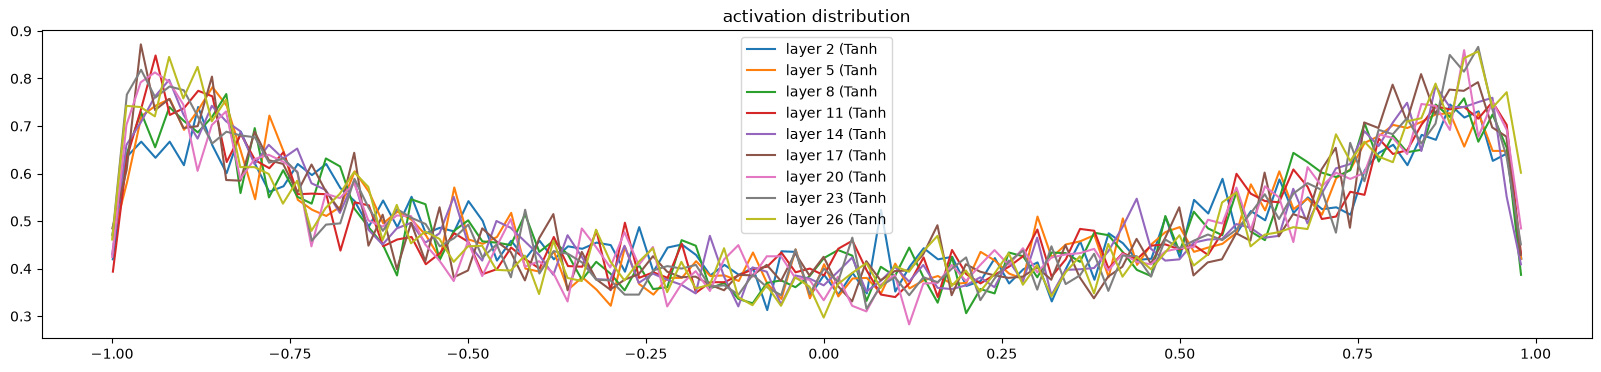

In [198]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out
    print('layer %d (%10s): mean %+.2f, std %.2f, saturated: %.2f%%' % (i, layer.__class__.__name__, t.mean(), t.std(), (t.abs() > 0.97).float().mean()*100))
    hy, hx = torch.histogram(t.cpu(), density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends)
plt.title('activation distribution');

layer 2 (      Tanh): mean +0.000000, std 1.375283e-03
layer 5 (      Tanh): mean -0.000000, std 1.239122e-03
layer 8 (      Tanh): mean -0.000000, std 1.118825e-03
layer 11 (      Tanh): mean +0.000000, std 1.044756e-03
layer 14 (      Tanh): mean -0.000000, std 9.603282e-04
layer 17 (      Tanh): mean -0.000000, std 9.250912e-04
layer 20 (      Tanh): mean -0.000000, std 8.610879e-04
layer 23 (      Tanh): mean -0.000000, std 8.055702e-04
layer 26 (      Tanh): mean +0.000001, std 7.244979e-04


Text(0.5, 1.0, 'gradient distribution')

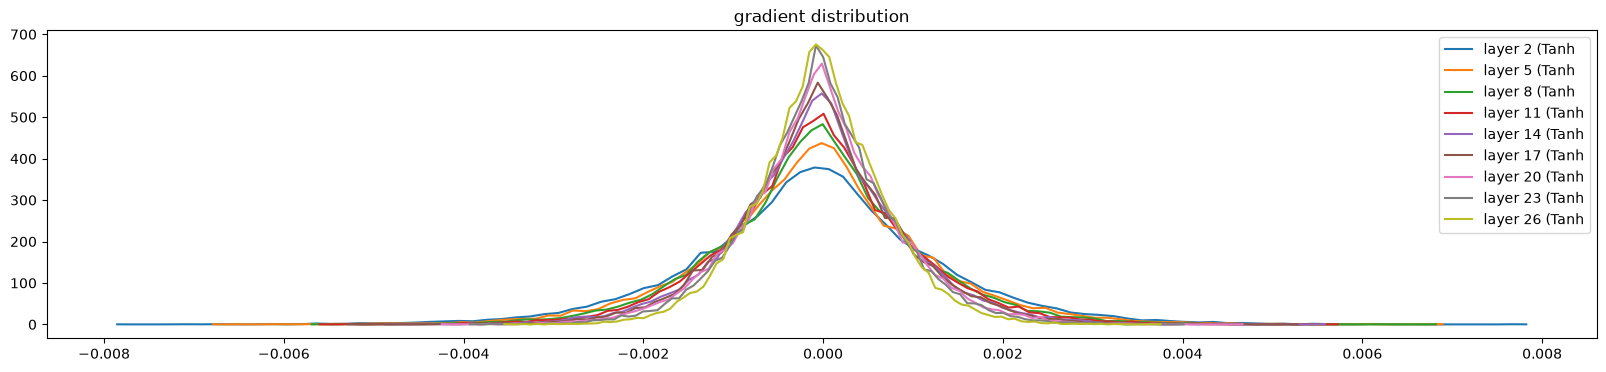

In [199]:
# Gradient Distribution
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i, layer in enumerate(layers[:-1]): # note: exclude the output layer
  if isinstance(layer, Tanh):
    t = layer.out.grad
    print('layer %d (%10s): mean %+f, std %e' % (i, layer.__class__.__name__, t.mean(), t.std()))
    hy, hx = torch.histogram(t.cpu(), density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'layer {i} ({layer.__class__.__name__}')
plt.legend(legends);
plt.title('gradient distribution')

weight   (27, 10) | mean +0.000000 | std 1.048048e-02 | grad:data ratio 1.113798e-02
weight  (300, 40) | mean -0.000044 | std 1.570951e-03 | grad:data ratio 1.572284e-03
weight (300, 300) | mean -0.000002 | std 5.106203e-04 | grad:data ratio 5.106092e-04
weight (300, 300) | mean -0.000000 | std 4.709664e-04 | grad:data ratio 4.717822e-04
weight (300, 300) | mean -0.000002 | std 4.315719e-04 | grad:data ratio 4.311897e-04
weight (300, 300) | mean -0.000001 | std 4.031122e-04 | grad:data ratio 4.018102e-04
weight (300, 300) | mean -0.000001 | std 3.885830e-04 | grad:data ratio 3.872724e-04
weight (300, 300) | mean -0.000000 | std 3.679483e-04 | grad:data ratio 3.689727e-04
weight (300, 300) | mean +0.000001 | std 3.484656e-04 | grad:data ratio 3.492282e-04
weight (300, 300) | mean -0.000001 | std 3.212390e-04 | grad:data ratio 3.207511e-04
weight  (27, 300) | mean +0.000000 | std 9.006619e-03 | grad:data ratio 9.598354e-02


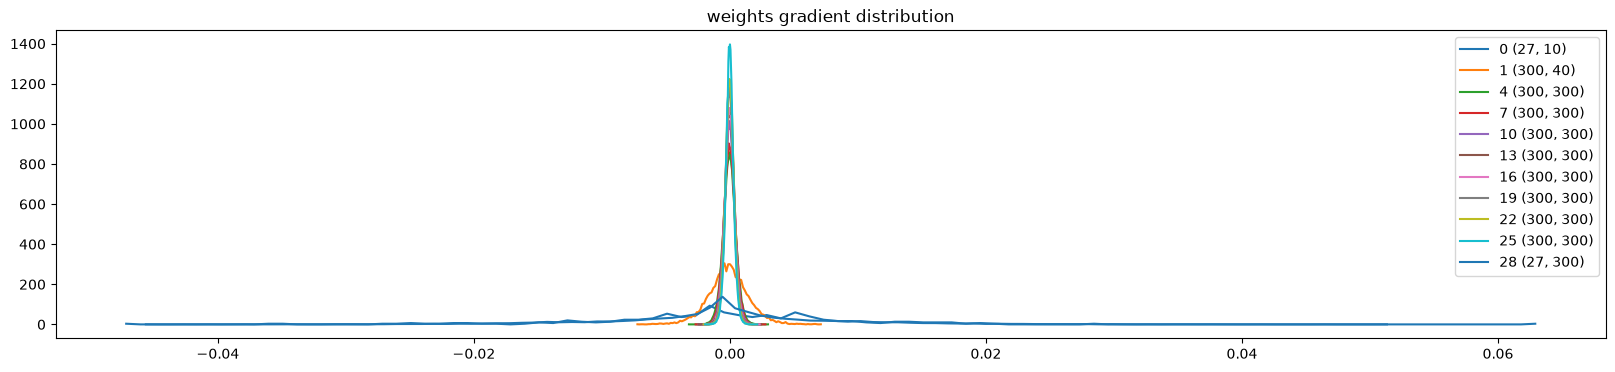

In [200]:
# visualize histograms
plt.figure(figsize=(20, 4)) # width and height of the plot
legends = []
for i,p in enumerate(parameters):
  t = p.grad
  if p.ndim == 2:
    print('weight %10s | mean %+f | std %e | grad:data ratio %e' % (tuple(p.shape), t.mean(), t.std(), t.std() / p.std()))
    hy, hx = torch.histogram(t.cpu(), density=True)
    plt.plot(hx[:-1].detach(), hy.detach())
    legends.append(f'{i} {tuple(p.shape)}')
plt.legend(legends)
plt.title('weights gradient distribution');

## 5. Evaluation & Inference

### 5.1 Model Evaluation (Test Loss)


In [ ]:
@torch.no_grad() # this decorator disables gradient tracking
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
    'test': (Xte, Yte),
  }[split]
  emb = C[x] # (N, block_size, n_embd)
  x = emb.view(emb.shape[0], -1) # concat into (N, block_size * n_embd)
  for layer in layers:
    x = layer(x)
  loss = F.cross_entropy(x, y)
  print(split, loss.item())

# put layers into eval mode
for layer in layers:
  layer.training = False
split_loss("train")
split_loss("val")

NameError: name 'layers' is not defined

In [ ]:
split_loss("test")

### 5.2 Sampling from the Model


In [25]:
# sample from the model
for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass the neural net
      emb = C[torch.tensor([context], device=device)] # (1,block_size,n_embd)
      x = emb.view(emb.shape[0], -1) # concatenate the vectors
      for layer in layers:
        x = layer(x)
      logits = x
      probs = F.softmax(logits, dim=1)
      # sample from the distribution (multinomial w/ CPU generator needs CPU probs)
      ix = torch.multinomial(probs.cpu(), num_samples=1, generator=g).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, break
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out)) # decode and print the generated word

hinda.
icelynn.
vyoletta.
ely.
yabs.
jasmee.
nina.
jamico.
berklie.
marlette.
aly.
jayden.
hallie.
kovu.
coen.
tara.
shal.
rayna.
alan.
sabella.
